# Ejercicio 04 · Clasificador visual con CNN y Model Card

**INF-8239 Ciencia de Datos II · Unidad 02 · U02.E04**

Autor: Edwin Ramón José Nolasco · Universidad Autónoma de Santo Domingo

Este cuaderno compara un baseline denso con una CNN en Fashion-MNIST, documenta la partición, evalúa calidad y costo, y presenta evidencia visual. No contiene resultados prefabricados: ejecute las celdas en orden.

## 1. Entorno

Se requiere Python 3.12. Esta ejecución se verificó en Windows 11 con TensorFlow 2.21 sobre CPU; TensorFlow no ofrece GPU en Windows nativo para esta versión. Linux, WSL2 o Google Colab son alternativas para GPU. La primera ejecución descarga Fashion-MNIST y requiere conexión a Internet. Instale las dependencias con `uv sync --extra cpu` y seleccione el kernel `.venv`.

In [1]:
from pathlib import Path

import json

import subprocess

import sys



ROOT = Path.cwd()

if not (ROOT / "scripts" / "train_cv.py").is_file():

    ROOT = ROOT.parent

if not (ROOT / "scripts" / "train_cv.py").is_file():

    raise FileNotFoundError("Abra el notebook desde la raíz del proyecto.")

print("Python:", sys.version.split()[0])

print("Proyecto:", ROOT)

Python: 3.12.14
Proyecto: C:\Users\pc\Desktop\info\Fraimel\Posgrado\Modulo #3\INF-8239 Ciencia de Datos II C2\Unidad 02 Procesamiento en Lenguaje Natural (NLP)\CV2


## 2. Auditoría, partición y entrenamiento

Se fija la semilla 42. El 10 % del conjunto de entrenamiento se separa estratificadamente para validación; la prueba oficial queda intacta hasta la evaluación final. Early stopping observa validación, no test. Si TensorFlow falla al importar, deténgase y ejecute el proyecto en WSL2/Linux o Colab.

In [2]:
run = subprocess.run(

    [sys.executable, str(ROOT / "scripts" / "train_cv.py"), "--epochs", "8"],

    cwd=ROOT,

    check=True,

    stdout=subprocess.PIPE,

    stderr=subprocess.STDOUT,

    text=True,

)

print(run.stdout)

audit = json.loads((ROOT / "reports" / "data_audit.json").read_text(encoding="utf-8"))

metrics = json.loads((ROOT / "reports" / "cv_metrics.json").read_text(encoding="utf-8"))

print("Conteos:", audit["counts"])

I0000 00:00:1790817942.131690   22476 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790817951.316341   22476 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790817955.783529   22476 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Epoch 1/8
E0000 00:00:1790817956.409939   22476 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpoo

## 3. Métricas y costo

Compare F1 macro, recall por clase, tamaño serializado, parámetros, tiempo de entrenamiento y latencia. La decisión técnica debe justificar si la mejora de la CNN compensa su costo; no seleccione por accuracy aislada.

In [3]:
for model_name, values in metrics.items():

    print(

        f"{model_name}: macro-F1={values['f1_macro']:.4f}; accuracy={values['accuracy']:.4f}; "

        f"parámetros={values['parameters']:,}; tamaño={values['model_size_bytes']:,} bytes; "

        f"entrenamiento={values['train_seconds']:.1f} s; "

        f"inferencia={values['inference_ms_per_image']:.4f} ms/imagen"

    )

    recalls = {name: round(values['per_class'][name]['recall'], 3) for name in audit['class_names']}

    print('Recall por clase:', recalls)

delta_f1 = metrics['cnn']['f1_macro'] - metrics['dense']['f1_macro']

print(f'Diferencia CNN - baseline en macro-F1: {delta_f1:+.4f}')

dense: macro-F1=0.8605; accuracy=0.8618; parámetros=50,890; tamaño=633,964 bytes; entrenamiento=23.7 s; inferencia=0.0425 ms/imagen
Recall por clase: {'T-shirt/top': 0.8, 'Trouser': 0.961, 'Pullover': 0.822, 'Dress': 0.931, 'Coat': 0.696, 'Sandal': 0.948, 'Shirt': 0.609, 'Sneaker': 0.944, 'Bag': 0.954, 'Ankle boot': 0.953}
cnn: macro-F1=0.7891; accuracy=0.7918; parámetros=19,466; tamaño=268,447 bytes; entrenamiento=124.6 s; inferencia=0.1419 ms/imagen
Recall por clase: {'T-shirt/top': 0.777, 'Trouser': 0.937, 'Pullover': 0.715, 'Dress': 0.858, 'Coat': 0.537, 'Sandal': 0.891, 'Shirt': 0.424, 'Sneaker': 0.94, 'Bag': 0.92, 'Ankle boot': 0.919}
Diferencia CNN - baseline en macro-F1: -0.0714


## 4. Evidencia visual

Revise curvas, matriz de confusión y ejemplos de error del conjunto de prueba. Explique las confusiones principales con evidencia; no atribuya causas que no haya contrastado.

training_curves.png


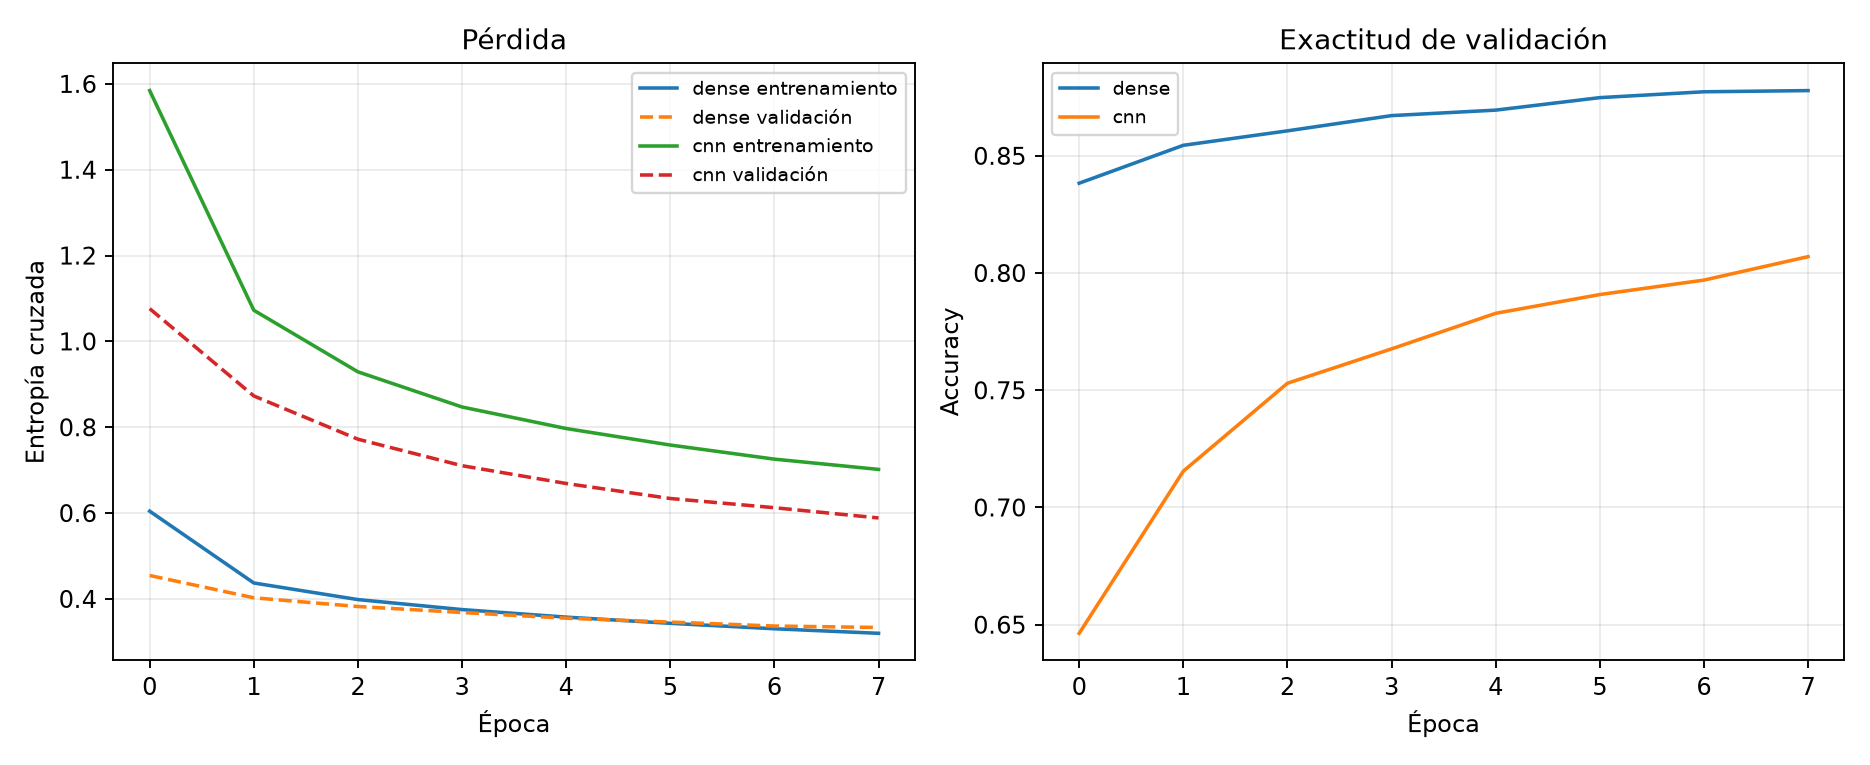

confusion_cnn.png


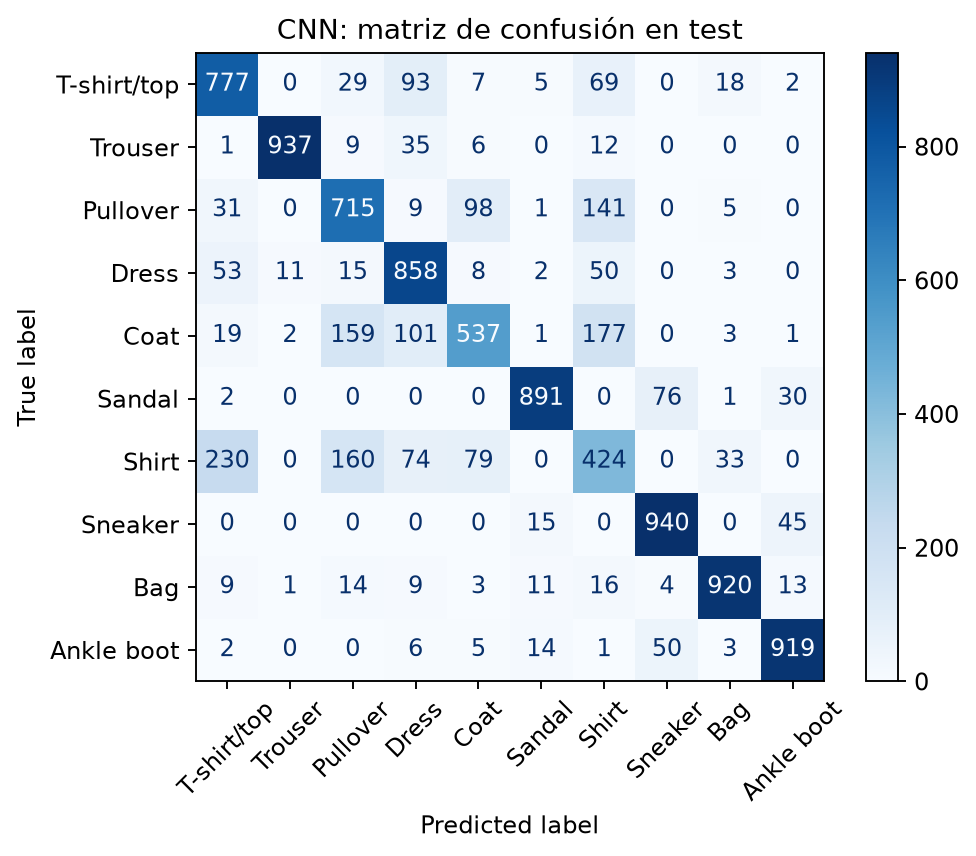

cnn_errors.png


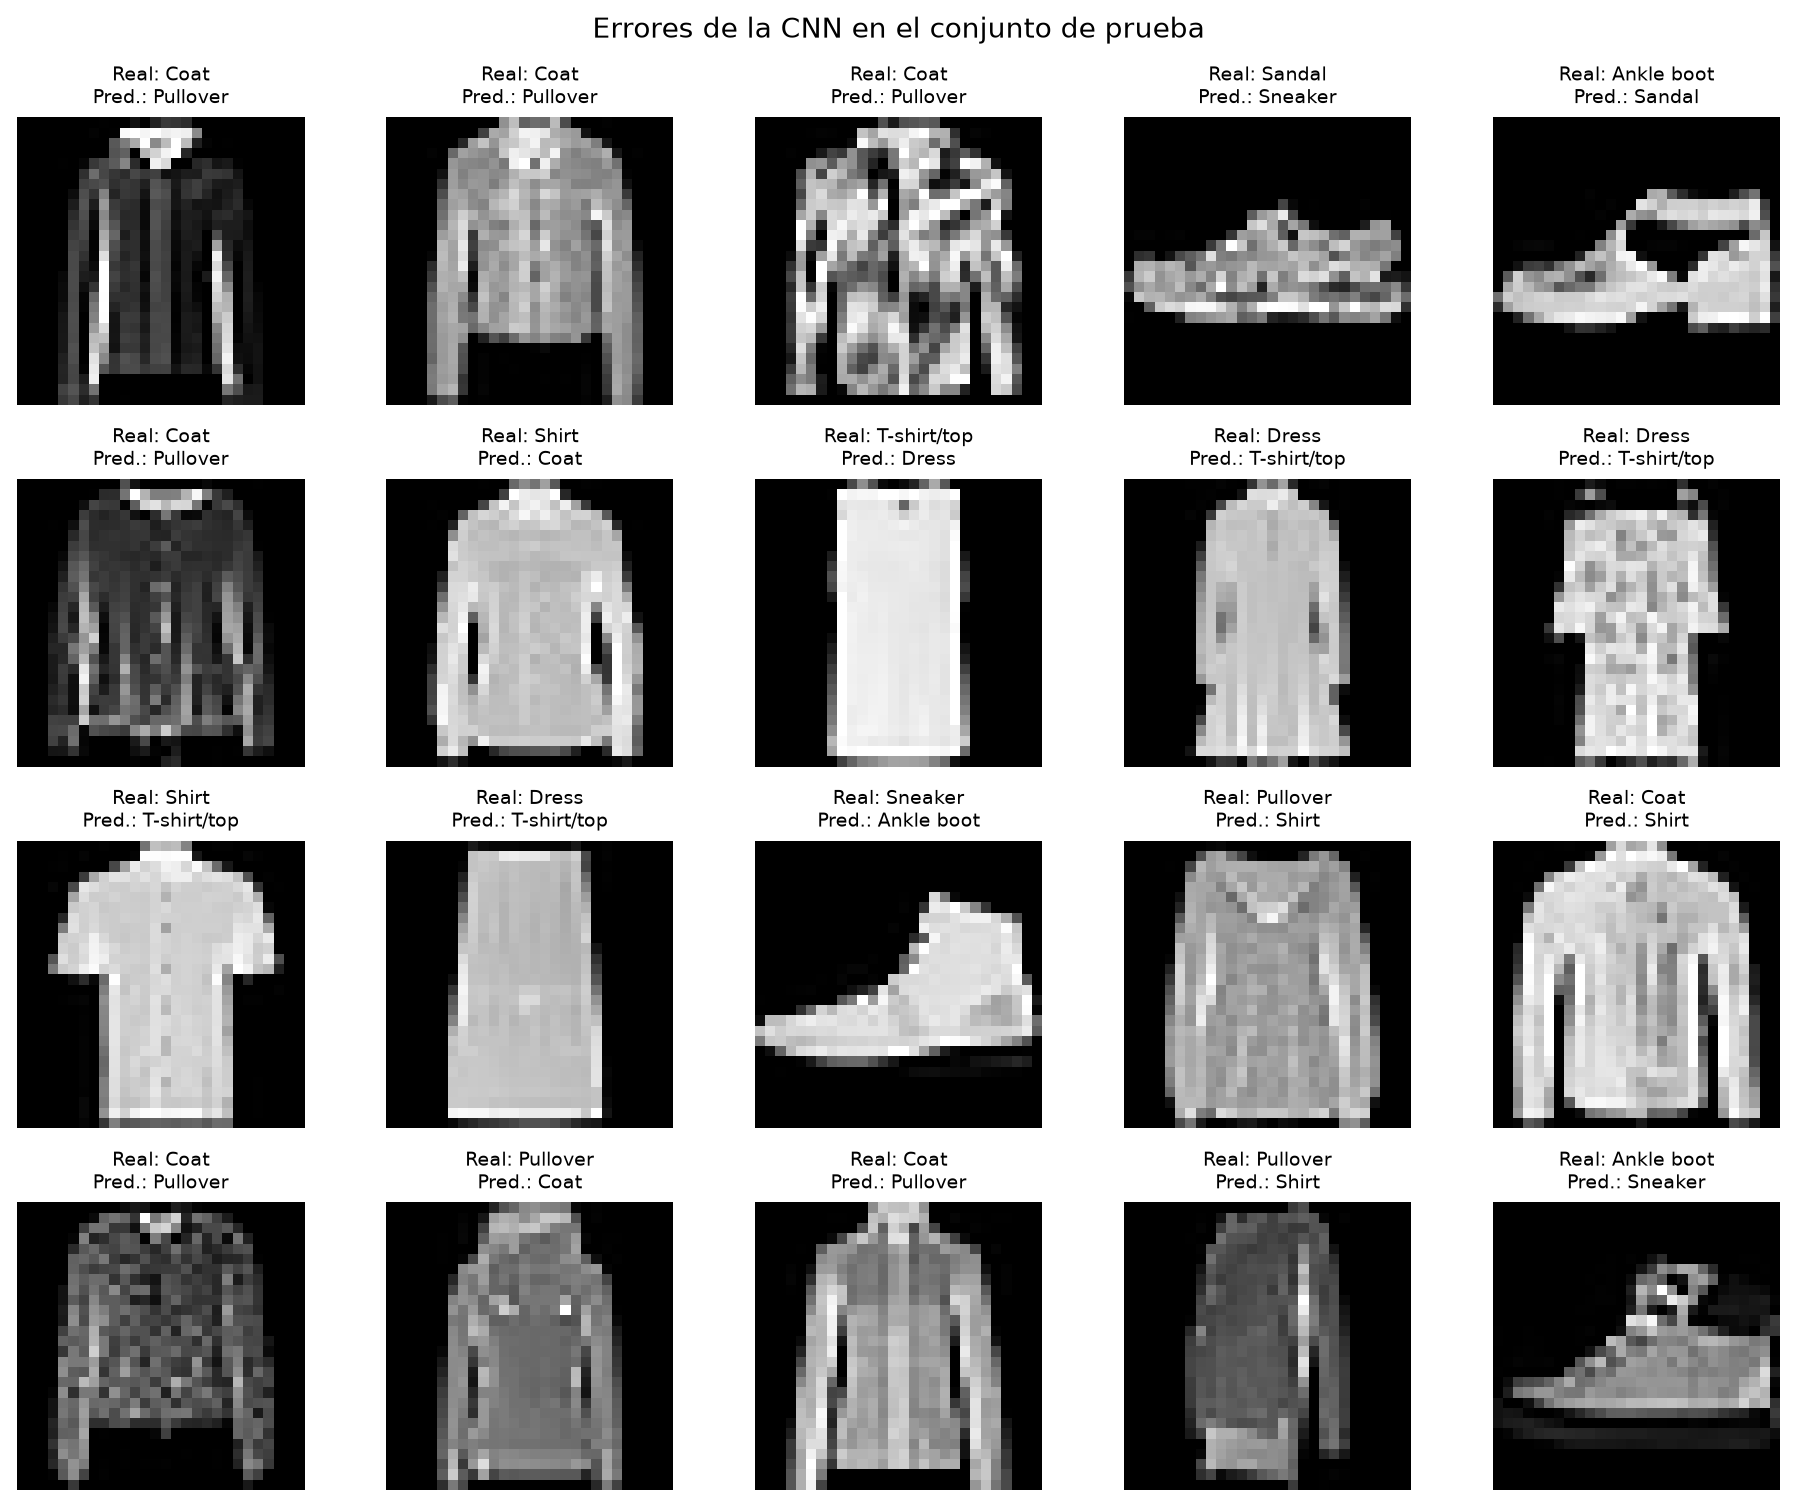

In [4]:
from IPython.display import Image, display



for filename in ('training_curves.png', 'confusion_cnn.png', 'cnn_errors.png'):

    print(filename)

    display(Image(filename=str(ROOT / 'reports' / filename)))

## 5. Cierre y entrega

Complete `MODEL_CARD.md` y genere `reports/U02_E04_informe.pdf` solo después de una corrida real. Publique el repositorio y configure `origin` para que el informe enlace a la dirección correcta.

Declare la herramienta de IA utilizada, prompts relevantes, partes verificadas y correcciones realizadas. El estudiante debe poder explicar el código, las métricas y la decisión. Fashion-MNIST es un benchmark educativo: no valida fotografías reales, imágenes médicas, OCR ni vigilancia.